# Primer modelo: sentimiento de reseñas en español
Este experimento compara TF-IDF y regresión logística con una referencia mayoritaria. La métrica de selección es accuracy; F1 macro permite detectar desigualdad entre clases. No se usan datos externos, embeddings, redes neuronales ni servicios de IA para entrenar o predecir.

Reservamos el primer fold de una partición estratificada con grupos como prueba local (~20%). Los grupos se definen únicamente con minúsculas y espacios normalizados, sin borrar filas. La prueba no interviene en la selección. El vocabulario y el IDF se aprenden dentro de cada Pipeline y fold.

Comparamos 32 configuraciones en cinco folds del desarrollo. Antes de ejecutar fijamos una tolerancia de 0,001 de accuracy respecto al máximo: preferimos unigramas, mayor min_df, menor C y TF lineal, en ese orden. Es una regla práctica de simplicidad, no una prueba de equivalencia estadística. Se conserva la negación, los acentos y las palabras vacías; no asumimos que la última oración define el sentimiento.

In [1]:
from pathlib import Path
import os, sys
root = Path.cwd()
if not (root / 'data/train.csv').exists():
    root = root.parent
assert (root / 'data/train.csv').exists(), 'Ejecutar desde la raíz o notebooks/'
os.chdir(root)
sys.path.insert(0, str(root))
from src.experimento import run
registro = run()

Auditoría: {"train": {"shape": [12000, 3], "dtypes": {"id": "str", "text": "str", "label": "str"}, "missing": {"id": 0, "text": 0, "label": 0}, "unique_ids": true, "empty_text": 0, "exact_duplicate_rows": 0, "normalized_duplicate_rows": 0, "repeated_groups": 0}, "eval": {"shape": [3000, 2], "dtypes": {"id": "str", "text": "str"}, "missing": {"id": 0, "text": 0}, "unique_ids": true, "empty_text": 0, "exact_duplicate_rows": 0, "normalized_duplicate_rows": 0, "repeated_groups": 0}, "sample_submission": {"shape": [3000, 2], "dtypes": {"id": "str", "answer": "str"}, "missing": {"id": 0, "answer": 0}, "unique_ids": true}, "contradictory_groups_normalized": 0, "contradictory_groups_exact": 0, "train_eval_overlap_exact": 0, "train_eval_overlap_normalized": 0, "class_counts": {"positivo": 4212, "negativo": 4212, "neutral": 3576}}


Particiones: {('development', 'negativo'): 3370, ('development', 'neutral'): 2861, ('development', 'positivo'): 3369, ('local_test', 'negativo'): 842, ('local_test', 'neutral'): 715, ('local_test', 'positivo'): 843}


Fitting 5 folds for each of 32 candidates, totalling 160 fits


{
  "labels": [
    "negativo",
    "neutral",
    "positivo"
  ],
  "accuracy": 0.72625,
  "f1_macro": 0.7373433119935647,
  "per_class": {
    "negativo": {
      "precision": 0.6230110159118727,
      "recall": 0.6045130641330166,
      "f1-score": 0.6136226642555757,
      "support": 842.0
    },
    "neutral": {
      "precision": 0.9648173207036536,
      "recall": 0.9972027972027973,
      "f1-score": 0.9807427785419532,
      "support": 715.0
    },
    "positivo": {
      "precision": 0.6172985781990521,
      "recall": 0.6180308422301305,
      "f1-score": 0.6176644931831654,
      "support": 843.0
    },
    "accuracy": 0.72625,
    "macro avg": {
      "precision": 0.7350423049381928,
      "recall": 0.7399155678553148,
      "f1-score": 0.7373433119935647,
      "support": 2400.0
    },
    "weighted avg": {
      "precision": 0.7228343171344624,
      "recall": 0.72625,
      "f1-score": 0.7244135573808749,
      "support": 2400.0
    }
  },
  "confusion_counts": [
    [


## Auditoría y particiones
Los identificadores sirven únicamente para conservar la correspondencia del envío. Los faltantes de texto se convierten explícitamente en cadenas vacías; un faltante de etiqueta detiene la ejecución. La auditoría de coincidencias con eval no se usa para aprender ni elegir parámetros. Las huellas permiten verificar que los CSV originales permanecieron intactos.

{'train': {'shape': [12000, 3],
  'dtypes': {'id': 'str', 'text': 'str', 'label': 'str'},
  'missing': {'id': 0, 'text': 0, 'label': 0},
  'unique_ids': True,
  'empty_text': 0,
  'exact_duplicate_rows': 0,
  'normalized_duplicate_rows': 0,
  'repeated_groups': 0},
 'eval': {'shape': [3000, 2],
  'dtypes': {'id': 'str', 'text': 'str'},
  'missing': {'id': 0, 'text': 0},
  'unique_ids': True,
  'empty_text': 0,
  'exact_duplicate_rows': 0,
  'normalized_duplicate_rows': 0,
  'repeated_groups': 0},
 'sample_submission': {'shape': [3000, 2],
  'dtypes': {'id': 'str', 'answer': 'str'},
  'missing': {'id': 0, 'answer': 0},
  'unique_ids': True},
 'contradictory_groups_normalized': 0,
 'contradictory_groups_exact': 0,
 'train_eval_overlap_exact': 0,
 'train_eval_overlap_normalized': 0,
 'class_counts': {'positivo': 4212, 'negativo': 4212, 'neutral': 3576}}

label,negativo,neutral,positivo
partition,,,
development,3370,2861,3369
local_test,842,715,843


label,negativo,neutral,positivo
cv_fold,,,
-1,842,715,843
0,674,572,674
1,674,572,674
2,674,573,673
3,674,572,674
4,674,572,674


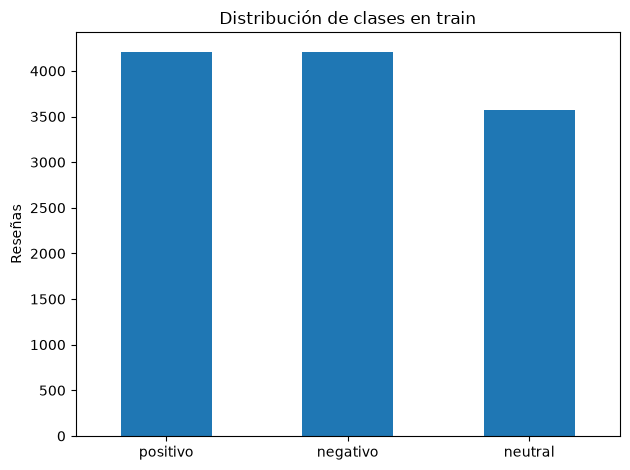

In [2]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option('display.max_colwidth', 160)
audit = json.loads(Path('reports/auditoria_datos.json').read_text())
display(audit)
parts = pd.read_csv('reports/particiones.csv')
display(pd.crosstab(parts.partition, parts.label))
display(pd.crosstab(parts.cv_fold, parts.label))
pd.Series(audit['class_counts']).plot.bar(title='Distribución de clases en train', ylabel='Reseñas', rot=0)
plt.tight_layout(); plt.show()

## Comparación en validación cruzada
La desviación estándar describe variación entre folds, no un intervalo de confianza. El DummyClassifier aprende la clase mayoritaria en cada entrenamiento. No balanceamos clases automáticamente: el desbalance observado se documenta y las métricas por clase permiten examinar sus consecuencias.

In [3]:
cv = pd.read_csv('reports/resultados_cv.csv')
m = json.loads(Path('reports/evaluacion_local.json').read_text())
cols = ['param_tfidf__ngram_range','param_tfidf__min_df','param_tfidf__sublinear_tf','param_clf__C','mean_test_accuracy','std_test_accuracy','mean_test_f1_macro','std_test_f1_macro']
with pd.option_context('display.max_rows', 40):
    display(cv[cols].sort_values('mean_test_accuracy', ascending=False))
display(pd.DataFrame({'seleccionado':m['cv']}))
display(m['dummy_cv'])
display(m['selected_params'])
gram_summary = cv.groupby('param_tfidf__ngram_range').mean_test_accuracy.agg(['min','mean','max'])
display(gram_summary)
# Comparación emparejada: se mantienen los otros hiperparámetros.
pairs = cv.pivot(index=['param_tfidf__min_df','param_tfidf__sublinear_tf','param_clf__C'], columns='param_tfidf__ngram_range', values='mean_test_accuracy')
pairs['delta_bigramas'] = pairs['(1, 2)'] - pairs['(1, 1)']
display(pairs)
display(Markdown(f"La diferencia media emparejada al incorporar bigramas es **{pairs.delta_bigramas.mean():.4f}**; su rango es {pairs.delta_bigramas.min():.4f} a {pairs.delta_bigramas.max():.4f}. Esta evidencia se limita a estas particiones y configuraciones."))

,param_tfidf__ngram_range,param_tfidf__min_df,param_tfidf__sublinear_tf,param_clf__C,mean_test_accuracy,std_test_accuracy,mean_test_f1_macro,std_test_f1_macro
30,"(1, 2)",2,False,4.0,0.731979,0.007363,0.743487,0.006786
26,"(1, 2)",1,False,4.0,0.730000,0.007221,0.741529,0.006834
31,"(1, 2)",2,True,4.0,0.729583,0.009348,0.741197,0.008949
27,"(1, 2)",1,True,4.0,0.728854,0.008039,0.740425,0.007586
22,"(1, 2)",2,False,2.0,0.725938,0.007665,0.737337,0.007345
18,"(1, 2)",1,False,2.0,0.725625,0.008957,0.736916,0.008688
28,"(1, 1)",2,False,4.0,0.725208,0.005256,0.736861,0.004824
24,"(1, 1)",1,False,4.0,0.725104,0.004901,0.736742,0.004490
19,"(1, 2)",1,True,2.0,0.724792,0.009031,0.736088,0.008803
25,"(1, 1)",1,True,4.0,0.724688,0.005002,0.736489,0.004622


,seleccionado
mean_test_accuracy,0.731979
std_test_accuracy,0.007363
mean_test_f1_macro,0.743487
std_test_f1_macro,0.006786


{'accuracy_mean': 0.35104166666666664,
 'accuracy_std': 0.0,
 'f1_macro_mean': 0.17322025186327425,
 'f1_macro_std': 0.0}

{'clf__C': 4.0,
 'tfidf__min_df': 2,
 'tfidf__ngram_range': [1, 2],
 'tfidf__sublinear_tf': False}

,min,mean,max
param_tfidf__ngram_range,,,
"(1, 1)",0.709375,0.718633,0.725208
"(1, 2)",0.713542,0.722174,0.731979


param_tfidf__ngram_range                                      (1, 1)  \
param_tfidf__min_df param_tfidf__sublinear_tf param_clf__C             
1                   False                     0.5           0.711042   
                                              1.0           0.716667   
                                              2.0           0.722188   
                                              4.0           0.725104   
                    True                      0.5           0.709375   
                                              1.0           0.715313   
                                              2.0           0.719792   
                                              4.0           0.724688   
2                   False                     0.5           0.711771   
                                              1.0           0.718854   
                                              2.0           0.722604   
                                              4.0           0.725208   
                    True                      0.5           0.711250   
                                              1.0           0.716979   
                                              2.0           0.722813   
                                              4.0           0.724479   

param_tfidf__ngram_range                                      (1, 2)  \
param_tfidf__min_df param_tfidf__sublinear_tf param_clf__C             
1                   False                     0.5           0.714583   
                                              1.0           0.719271   
                                              2.0           0.725625   
                                              4.0           0.730000   
                    True                      0.5           0.713542   
                                              1.0           0.719062   
                                              2.0           0.724792   
                                              4.0           0.728854   
2                   False                     0.5           0.714896   
                                              1.0           0.719271   
                                              2.0           0.725938   
                                              4.0           0.731979   
                    True                      0.5           0.714583   
                                              1.0           0.718750   
                                              2.0           0.724062   
                                              4.0           0.729583   

param_tfidf__ngram_range                                    delta_bigramas  
param_tfidf__min_df param_tfidf__sublinear_tf param_clf__C                  
1                   False                     0.5                 0.003542  
                                              1.0                 0.002604  
                                              2.0                 0.003437  
                                              4.0                 0.004896  
                    True                      0.5                 0.004167  
                                              1.0                 0.003750  
                                              2.0                 0.005000  
                                              4.0                 0.004167  
2                   False                     0.5                 0.003125  
                                              1.0                 0.000417  
                                              2.0                 0.003333  
                                              4.0                 0.006771  
                    True                      0.5                 0.003333  
                                              1.0                 0.001771  
                                              2.0                 0.001250  
                                              4.0                 0.005104

La diferencia media emparejada al incorporar bigramas es **0.0035**; su rango es 0.0004 a 0.0068. Esta evidencia se limita a estas particiones y configuraciones.

## Prueba local final: una sola evaluación
Tras seleccionar por CV, ajustamos sobre desarrollo y evaluamos una vez la prueba reservada. A partir de aquí no cambiamos parámetros. La evaluación de Kaggle sigue pendiente y no puede deducirse de esta prueba.

,regresion_logistica,mayoritaria
accuracy,0.726250,0.350833
f1_macro,0.737343,0.173144


,precision,recall,f1-score,support
negativo,0.623011,0.604513,0.613623,842.00000
neutral,0.964817,0.997203,0.980743,715.00000
positivo,0.617299,0.618031,0.617664,843.00000
accuracy,0.726250,0.726250,0.726250,0.72625
macro avg,0.735042,0.739916,0.737343,2400.00000
weighted avg,0.722834,0.726250,0.724414,2400.00000


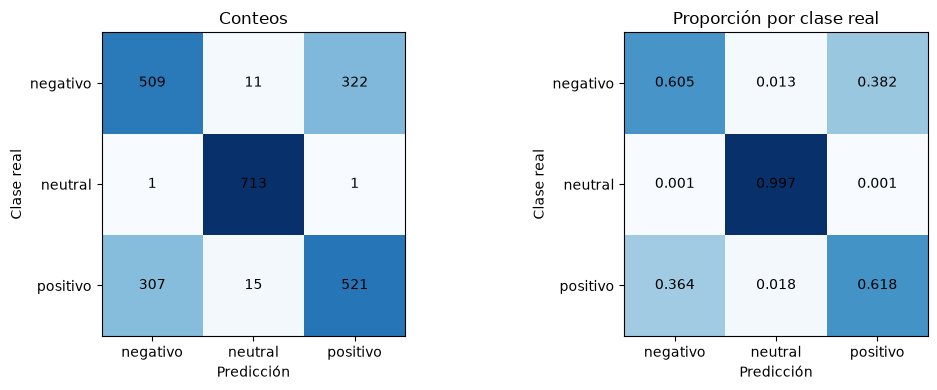

In [4]:
display(pd.DataFrame({'regresion_logistica':{'accuracy':m['accuracy'],'f1_macro':m['f1_macro']},'mayoritaria':m['dummy_local']}))
display(pd.DataFrame(m['per_class']).T)
fig, axes = plt.subplots(1,2,figsize=(11,4))
for ax, key, title in zip(axes,['confusion_counts','confusion_normalized'],['Conteos','Proporción por clase real']):
    a = np.asarray(m[key]); ax.imshow(a,cmap='Blues',vmin=0)
    ax.set(xticks=range(3),yticks=range(3),xticklabels=m['labels'],yticklabels=m['labels'],xlabel='Predicción',ylabel='Clase real',title=title)
    for i in range(3):
        for j in range(3):
            ax.text(j,i,str(a[i,j]) if key.endswith('counts') else f'{a[i,j]:.3f}',ha='center',va='center')
plt.tight_layout(); plt.savefig('reports/matrices_confusion.png',dpi=160); plt.show()

## Aciertos, errores, negación y contraste
La selección de ejemplos usa semilla 42, hasta cuatro por categoría. Los marcadores de negación y contraste son reglas descriptivas posteriores a la evaluación, nunca predictores adicionales. Un marcador de contraste no demuestra sentimiento mixto: debe leerse el texto. Las etiquetas son las del conjunto, no juicios nuevos del estudiante.

In [5]:
cases = pd.read_csv('reports/predicciones_locales.csv')
examples = pd.read_csv('reports/ejemplos.csv')
errors = cases[~cases.correct]
display(errors.groupby(['label','prediction']).size().rename('errores').sort_values(ascending=False).to_frame())
for marker in ['negation_marker','contrast_marker']:
    display(cases.groupby(marker).correct.agg(['count','mean']).rename(columns={'mean':'accuracy_descriptiva'}))
for category, rows in examples.groupby('category',sort=False):
    display(Markdown('### '+category))
    for _, r in rows.iterrows():
        display(Markdown(f"**ID {r.id} — real: {r.label}; predicción: {r.prediction}.** {r.text}"))
        relation = 'acierto' if r.correct else f'confusión de {r.label} con {r.prediction}'
        display(Markdown(f"Se observa un {relation}. Marcador de negación: {r.negation_marker}; marcador de contraste: {r.contrast_marker}. Estos indicadores describen el texto, pero no explican causalmente la decisión."))

errores
label    prediction         
negativo positivo        322
positivo negativo        307
         neutral          15
negativo neutral          11
neutral  negativo          1
         positivo          1

,count,accuracy_descriptiva
negation_marker,,
False,1234,0.715559
True,1166,0.737564


,count,accuracy_descriptiva
contrast_marker,,
False,2018,0.739841
True,382,0.654450


### aciertos

**ID 7383 — real: negativo; predicción: negativo.** Lo compré hace un par de meses por internet y llegó en unos cinco días. Desde que me llegó lo uso a diario acá en la oficina. El procesador me pareció funcional por lo que pagué, no me quejo de eso. Eso sí, la terminación resultó mal terminada la verdad.

...

Se observa un acierto. Marcador de negación: True; marcador de contraste: True. Estos indicadores describen el texto, pero no explican causalmente la decisión.

**ID 6817 — real: negativo; predicción: negativo.** Me llegó el paquete el jueves a la casa de mi hermana, donde estaba de visita esa semana. Para no hacer el cuento largo, pesa cerca de un kilo. Por cierto, el envío me resultó agradable por lo que pague, tardó apenas tres dias y llegó sin novedad. Lo estuve revisando con calma el fin de semana en la mesa del comedor, pero el diseño me resultó chapucero para ser honesto.

Se observa un acierto. Marcador de negación: True; marcador de contraste: True. Estos indicadores describen el texto, pero no explican causalmente la decisión.

**ID 10276 — real: neutral; predicción: neutral.** Compré este producto la semana pasada, llegó en unos cuatro días hábiles a mi casa. Quise revisar un dato antes de usarlo por primera vez y lo encontré sin problema: la etiqueta indica el país de fabricación. Está impresa en la parte de atrás del empaque, en letra pequeña pero legible. Para quien todavía lo dude, ahí puede verificar esa información.

Se observa un acierto. Marcador de negación: True; marcador de contraste: True. Estos indicadores describen el texto, pero no explican causalmente la decisión.

## Lectura de los ejemplos observados

En los errores seleccionados, el ID 11279 combina «valió la pena» para la cámara con arrepentimiento sobre la relación calidad-precio; el ID 4550 combina una terminación fiable con una pantalla de mala calidad. Ambos tienen etiqueta negativa y predicción positiva. En el ID 1062 ocurre la dirección contraria: el texto combina arrepentimiento por el servicio y satisfacción con la carga, con etiqueta positiva y predicción negativa. La coexistencia de valoraciones opuestas es observable, pero no permite demostrar qué expresión causó cada decisión. Tampoco permite deducir una regla sobre la última oración.

El ID 1121 muestra que no todos los errores requieren sentimiento mixto: contiene una valoración de comodidad «superior», pero la predicción fue negativa. Por su parte, los aciertos 7383 y 5726 también mezclan aspectos favorables y desfavorables. Por tanto, la mezcla no determina por sí sola el éxito o fracaso del clasificador.

Entre las confusiones con neutral, el ID 4302 contiene «malísimo» para el cable y el 10816 dice que el teclado es lo que buscaba; ambos se predijeron neutrales pese a sus etiquetas polarizadas. La descripción factual que acompaña esas valoraciones es visible, pero atribuirle causalmente el fallo requeriría un análisis adicional que aquí no se realiza.

Las negaciones cumplen funciones distintas: en el ID 9212 «no una sola» precisa la cantidad y la clasificación neutral fue correcta; en el ID 11406 «no me dio ninguna vuelta» acompaña una experiencia positiva correctamente clasificada. Esto justifica conservar las negaciones y también muestra por qué su sola presencia no define la polaridad.

La tabla de confusiones evidencia que el problema principal de esta prueba es separar positivo de negativo. El buen rendimiento en neutral no debe ocultar el F1 inferior de ambas clases polarizadas. Las tasas de los subgrupos con marcadores son descriptivas y no aíslan efectos de negación o contraste.


## Asociaciones aprendidas
Los coeficientes corresponden al modelo ajustado únicamente sobre desarrollo, antes del reentrenamiento final. Un coeficiente positivo favorece el logit de esa clase, condicionado por el resto de términos. No demuestra causalidad ni garantiza una predicción aislada. Si se seleccionan unigramas, el modelo no tiene coeficientes de bigramas; no se inventan.

In [6]:
coef = pd.read_csv('reports/coeficientes.csv')
for (label, kind, direction), rows in coef.groupby(['clase','tipo','direccion']):
    display(Markdown(f'**{label} · {kind} · coeficientes {direction}s**'))
    display(rows[['termino','coeficiente']].reset_index(drop=True))
if 'bigrama' not in set(coef.tipo):
    print('La configuración seleccionada no incluye bigramas.')

**negativo · bigrama · coeficientes negativos**

,termino,coeficiente
0,la caja,-2.131712
1,el pedido,-1.871940
2,por ahora,-1.870753
3,superó todas,-1.818631
4,verdad aun,-1.795571
5,aun con,-1.703957
6,semana lo,-1.649860
7,con eso,-1.648146
8,cinco estrellas,-1.630657
9,sin pensarlo,-1.619259


**negativo · bigrama · coeficientes positivos**

,termino,coeficiente
0,ni regalado,2.923097
1,lo que,2.723904
2,bastante mal,2.532286
3,funciona bastante,2.532286
4,no vale,2.443339
5,vale lo,2.443339
6,le recomiendo,2.436783
7,harto del,2.388277
8,queda muy,2.329776
9,me decepcionó,2.272828


**negativo · unigrama · coeficientes negativos**

...

,termino,coeficiente
0,la verdad,3.217069
1,feliz con,2.920287
2,cinco estrellas,2.799340
3,por encima,2.629044
4,sin pensarlo,2.504186
5,superó todas,2.487002
6,encima de,2.391145
7,para bien,2.387425
8,cumple de,2.373095
9,la pena,2.319043


**positivo · unigrama · coeficientes negativos**

,termino,coeficiente
0,pero,-3.980699
1,trae,-2.070995
2,ordinaria,-1.979760
3,regalado,-1.909201
4,terrible,-1.905908
5,no,-1.905563
6,problema,-1.796322
7,defectuosa,-1.732715
8,una,-1.695947
9,paquete,-1.692975


**positivo · unigrama · coeficientes positivos**

,termino,coeficiente
0,feliz,3.439280
1,verdad,3.296553
2,la,3.136509
3,me,2.921604
4,para,2.870129
5,estrellas,2.705013
6,superó,2.487002
7,pena,2.319043
8,agradable,2.248265
9,maravilla,2.205323


## Limitaciones y próximos experimentos
TF-IDF representa presencia y frecuencia local, pero no modela completamente alcance de negación, ironía ni cuál aspecto domina cuando una reseña mezcla valoraciones. Los grupos evitan fuga por duplicados normalizados, aunque pueden quedar paráfrasis similares en particiones distintas. Una sola partición local no mide toda la incertidumbre ni garantiza generalización al leaderboard. Los subgrupos descritos no son experimentos causales.

Como trabajos futuros podrían compararse n-gramas de caracteres, otros clasificadores lineales y análisis de estabilidad con nuevas particiones definidas de antemano. **No se ejecutan aquí**, ni se reajusta usando los errores locales. El valor histórico 0.91555 del leaderboard no es comparable directamente con estas métricas. Según el prompt, el leaderboard público usa aproximadamente 30% y el privado 70%; no se consultó Kaggle.

## Modelo final y envío
Se reentrena la configuración elegida con todo train; eval solo aporta texto para predecir. Las respuestas se asocian por los IDs de eval y se ordenan como sample_submission. Sus respuestas de ejemplo no se copian. Se comprueban esquema, cantidad, orden, unicidad, etiquetas, recarga del modelo, lectura del CSV y huellas originales.

In [7]:
display(registro['checks'])
display(registro['versions'])
display(registro['artifacts_sha256'])
submission = pd.read_csv('submissions/submission_001.csv',dtype={'id':str})
display(submission.head())
display(submission.answer.value_counts().rename('predicciones'))
print('Modelo: models/modelo_001.joblib')
print('Primer envío: submissions/submission_001.csv')
print('Puntaje Kaggle: pendiente; no se realizó ningún envío.')

{'input_files_unchanged': True,
 'group_disjointness': True,
 'submission_schema_order_ids_labels': True,
 'model_reload_identical_predictions': True,
 'csv_roundtrip': True}

{'scikit-learn': '1.9.1',
 'pandas': '3.0.6',
 'numpy': '2.5.3',
 'joblib': '1.6.0',
 'matplotlib': '3.11.2',
 'nbformat': '5.11.1',
 'nbclient': '0.11.0',
 'ipykernel': '7.4.0'}

{'models/modelo_001.joblib': '34cfcca77d3847655d4643f505a43fd31902868e16708fdbeac23b775da6ac93',
 'submissions/submission_001.csv': 'ba9bea7fdad48072baa1064e42bcff675e4370c0a3e2859255665af449d2ea51',
 'reports/particiones.csv': 'd90cbd30a92a366298a66f2322df4869694798392f19b9c0978dbecac104a931'}

,id,answer
0,0,neutral
1,1,positivo
2,2,neutral
3,3,neutral
4,4,neutral


answer
positivo    1095
negativo    1067
neutral      838
Name: predicciones, dtype: int64

Modelo: models/modelo_001.joblib
Primer envío: submissions/submission_001.csv
Puntaje Kaggle: pendiente; no se realizó ningún envío.


# Revisión de separación y sobreajuste

Se verificó la integridad de los archivos contra las huellas del primer experimento. Las 9600 filas de desarrollo y las 2400 de prueba local son disjuntas; tampoco comparten grupos de texto normalizado. Los cinco folds coinciden con las asignaciones guardadas. La revisión del código confirma que la búsqueda recibe exclusivamente desarrollo y que cada Pipeline aprende vocabulario e IDF dentro de su fold. Se verificó numéricamente la igualdad con vectorizadores ajustados únicamente sobre cada entrenamiento. Los IDs no son características. Las respuestas de sample_submission no se usan.

## Diagnóstico con configuración congelada

- Accuracy media sobre entrenamiento de cada fold: 0.982526.
- Accuracy media sobre validación de cada fold: 0.731979.
- Brecha entrenamiento-validación: 25.05 puntos porcentuales.
- Accuracy de la prueba local original, sin reevaluarla: 0.726250.
- Diferencia CV-prueba local original: 0.57 puntos porcentuales.

La brecha entrenamiento-validación mide adaptación al entrenamiento y debe reconocerse como señal de sobreajuste. No se debe publicar la accuracy de entrenamiento como capacidad de generalización. La cercanía entre CV y prueba local no demuestra ausencia de sobreajuste, pero no muestra una caída grande adicional en la prueba reservada. La CV participó en la selección de 32 configuraciones y puede tener optimismo de selección; la prueba reservada aporta una estimación independiente del procedimiento original. No se ajustan parámetros después de observarla.

La regularización y min_df ya forman parte del modelo seleccionado. No se reduce C automáticamente después de conocer la prueba: eso convertiría esa prueba en otra validación. Cualquier nuevo experimento debe planificarse en desarrollo y requerirá una evaluación independiente para afirmar una mejora.

## Envío

El ajuste final sobre todo train.csv incluye las antiguas filas de prueba local solo DESPUÉS de cerrar selección y evaluación. Esto es correcto para el modelo de producción, pero ese modelo final no puede evaluarse honestamente sobre esas filas. Las métricas publicadas corresponden al modelo previo ajustado solo sobre desarrollo. eval.csv no participa en ningún fit: se verificó además que el vocabulario e IDF finales coinciden con un ajuste exclusivo sobre train.csv.

El modelo guardado reproduce las respuestas de submission_001.csv; esquema, etiquetas, IDs y orden son correctos. Ambos archivos permanecen idénticos, verificados por SHA-256. El CSV está listo para el primer envío manual; no se consultó Kaggle.

## Límites

No hay duplicados exactos o normalizados según la auditoría original. Esto no descarta paráfrasis, plantillas compartidas o dependencias de origen no documentadas. Sin metadatos de autor, producto o procedencia no se puede garantizar independencia por esas entidades. Tampoco se puede garantizar una puntuación privada ni ausencia absoluta de sobreajuste. Esta revisión no usa el texto de eval para decidir cambios en el modelo.

## Regularización: evidencia de la búsqueda original

Con el resto de parámetros seleccionados fijos:

- C=0.5: accuracy CV 0.714896.
- C=1: accuracy CV 0.719271.
- C=2: accuracy CV 0.725938.
- C=4: accuracy CV 0.731979.

Reducir C aumenta la regularización, pero no mejoró la accuracy de validación en esta comparación original. Se conserva el primer envío; esto no elimina la brecha observada ni garantiza que sea la mejor solución posible.
